# TRACE — Qwen2.5-7B — 1-Day Colab Edition

A resumable implementation of the 2023 TRACE continual-learning benchmark using **one model: Qwen/Qwen2.5-7B-Instruct**.

### Designed for a one-day project
- automatic official TRACE benchmark download
- recursive JSON discovery (no hard-coded extracted-folder layout)
- 4-bit QLoRA
- official 8-task order
- task-by-task checkpoints and resume
- configurable `SMOKE`, `ONE_DAY`, and `PAPER_SCALE` modes
- OP/BWT + forgetting matrix
- optional FAAR adaptive replay contribution
- final results ZIP

**Recommended:** start with `SMOKE`, then run `ONE_DAY`. `PAPER_SCALE` is optional if time/GPU allow it.

This is a controlled TRACE reimplementation with Qwen2.5-7B, not an exact reproduction of the original model/training environment.


In [1]:
# =========================
# 0. CONFIG — EDIT HERE ONLY
# =========================
RUN_MODE = "ONE_DAY"     # SMOKE / ONE_DAY / PAPER_SCALE
MODEL_NAME = "Qwen/Qwen2.5-7B-Instruct"
ENABLE_FAAR = False      # False = baseline; True = FAAR contribution
RESUME = True
SEED = 42
SAVE_PREDICTIONS = True

# Infrastructure-only controls (do not change the experiment itself)
GPU_INDEX = 0
COLAB_USE_DRIVE = False
AUTO_INSTALL_ON_COLAB = True

MODES = {
    "SMOKE": dict(train=100, eval=50, eval_items=20, replay=40, max_len=512, new_tokens=48),
    "ONE_DAY": dict(train=1000, eval=500, eval_items=150, replay=200, max_len=768, new_tokens=64),
    "PAPER_SCALE": dict(train=5000, eval=2000, eval_items=500, replay=400, max_len=768, new_tokens=96),
}
if RUN_MODE not in MODES:
    raise ValueError("RUN_MODE must be SMOKE, ONE_DAY, or PAPER_SCALE")
CFG = MODES[RUN_MODE]
print(RUN_MODE, MODEL_NAME, CFG, "FAAR=", ENABLE_FAAR)


ONE_DAY Qwen/Qwen2.5-7B-Instruct {'train': 1000, 'eval': 500, 'eval_items': 150, 'replay': 200, 'max_len': 768, 'new_tokens': 64} FAAR= False


In [2]:
import os, sys, json, random, re, gc, time, shutil, zipfile
from pathlib import Path
from collections import Counter

IS_COLAB = "google.colab" in sys.modules or bool(os.environ.get("COLAB_RELEASE_TAG"))

# On CNAM, select one physical GPU before importing torch.
# If CUDA_VISIBLE_DEVICES was already set when Jupyter was launched, keep it.
if not IS_COLAB and "CUDA_VISIBLE_DEVICES" not in os.environ:
    os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU_INDEX)

import numpy as np, pandas as pd, torch

if not torch.cuda.is_available():
    raise RuntimeError("GPU not detected. In Colab: Runtime > Change runtime type > GPU")

gpu = torch.cuda.get_device_name(0)
vram = torch.cuda.get_device_properties(0).total_memory / 1024**3
print("Environment:", "Google Colab" if IS_COLAB else "CNAM/Linux")
print("GPU:", gpu, "VRAM:", round(vram, 1), "GB")
print("Visible CUDA devices:", torch.cuda.device_count())

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

if IS_COLAB and COLAB_USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORKSPACE_ROOT = Path("/content/drive/MyDrive/TRACE_QWEN_RUNS")
elif IS_COLAB:
    WORKSPACE_ROOT = Path("/content/TRACE_QWEN_RUNS")
else:
    WORKSPACE_ROOT = Path.home() / "TRACE_QWEN_RUNS"

# Crucial: every mode/method gets an independent state/checkpoint tree.
TAG = f"{RUN_MODE}_{'FAAR' if ENABLE_FAAR else 'BASELINE'}"
BASE = WORKSPACE_ROOT / TAG
DATA_ROOT = WORKSPACE_ROOT / "_shared_data"
RUN_ROOT = BASE / "run"
CKPT = RUN_ROOT / "checkpoints"
OUT = RUN_ROOT / "results"

for x in [WORKSPACE_ROOT, BASE, DATA_ROOT, RUN_ROOT, CKPT, OUT]:
    x.mkdir(parents=True, exist_ok=True)

STATE_FILE = RUN_ROOT / "state.json"
if STATE_FILE.exists() and RESUME:
    STATE = json.loads(STATE_FILE.read_text(encoding="utf-8"))
else:
    STATE = {"completed": [], "results": {}, "best": {}, "latest": {}}

print("Run tag:", TAG)
print("Workspace:", WORKSPACE_ROOT)
print("Run root:", BASE)
print("Already completed:", STATE.get("completed", []))


Environment: CNAM/Linux
GPU: NVIDIA A40 VRAM: 44.4 GB
Visible CUDA devices: 1
Run tag: ONE_DAY_BASELINE
Workspace: /users/q/qaisarm/TRACE_QWEN_RUNS
Run root: /users/q/qaisarm/TRACE_QWEN_RUNS/ONE_DAY_BASELINE
Already completed: []


## 1. Install modern dependencies

The original TRACE repository uses an older environment. This notebook uses current Hugging Face tooling for Qwen2.5 and 4-bit QLoRA.


In [3]:
import importlib.util, subprocess

PKGS = [
    "transformers>=4.45,<5",
    "datasets>=2.20,<4",
    "accelerate>=0.34",
    "peft>=0.13",
    "bitsandbytes>=0.43",
    "gdown>=5.2",
    "sentencepiece",
    "safetensors",
    "scikit-learn",
    "rouge-score",
]

if IS_COLAB and AUTO_INSTALL_ON_COLAB:
    print("Colab detected: ensuring required packages are installed...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", *PKGS])
    print("Dependency installation complete.")
else:
    required_modules = ["transformers", "datasets", "accelerate", "peft", "bitsandbytes", "gdown"]
    missing = [m for m in required_modules if importlib.util.find_spec(m) is None]
    if missing:
        raise RuntimeError(
            "Missing packages: " + ", ".join(missing) +
            ". Activate the CNAM virtual environment before launching Jupyter."
        )
    print("Using dependencies from the current Python environment.")


Using dependencies from the current Python environment.


## 2. Download and extract the official TRACE benchmark

The key fix for the previous `Candidate dataset folders: 0` error: the notebook **does not assume any extracted folder layout**. It recursively finds every JSON file and resolves tasks/splits from their names and paths.


In [4]:
TRACE_DRIVE_ID="1S0SmU0WEw5okW_XvP2Ns0URflNzZq6sV"
ZIP=DATA_ROOT/'TRACE-Benchmark.zip'; ROOT=DATA_ROOT/'extracted'
import gdown
if not ZIP.exists() or ZIP.stat().st_size<10000:
    gdown.download(f"https://drive.google.com/uc?id={TRACE_DRIVE_ID}",str(ZIP),quiet=False)
if not ZIP.exists() or ZIP.stat().st_size<10000: raise RuntimeError("TRACE benchmark download failed")
if not ROOT.exists() or not any(ROOT.rglob('*')):
    if ROOT.exists(): shutil.rmtree(ROOT)
    ROOT.mkdir(parents=True)
    with zipfile.ZipFile(ZIP) as z: z.extractall(ROOT)
print("Archive:",ZIP,"Extracted:",ROOT)


Archive: /users/q/qaisarm/TRACE_QWEN_RUNS/_shared_data/TRACE-Benchmark.zip Extracted: /users/q/qaisarm/TRACE_QWEN_RUNS/_shared_data/extracted


In [5]:
TASKS=["C-STANCE","FOMC","MeetingBank","Py150","ScienceQA","NumGLUE-cm","NumGLUE-ds","20Minuten"]
ALIASES={
"C-STANCE":["c-stance","cstance","c_stance"],"FOMC":["fomc"],"MeetingBank":["meetingbank","meeting-bank","meeting_bank"],"Py150":["py150"],"ScienceQA":["scienceqa","science-qa","science_qa"],"NumGLUE-cm":["numglue-cm","numglue_cm","numgluecm"],"NumGLUE-ds":["numglue-ds","numglue_ds","numglueds"],"20Minuten":["20minuten","20-minuten","20_minuten"]}
SPLITS={"train":["train"],"eval":["eval","dev","validation","valid"],"test":["test"]}
def norm(x): return re.sub(r'[^a-z0-9]+','',str(x).lower())
files=sorted(list(ROOT.rglob('*.json'))+list(ROOT.rglob('*.JSON')))
print('JSON files:',len(files))
for f in files: print(' ',f.relative_to(ROOT))
if not files: raise RuntimeError('No JSON files found in TRACE archive')

def score_task(t,p):
    s=norm(p); return max([len(norm(a)) for a in ALIASES[t] if norm(a) in s] or [0])
def score_split(s,p):
    stem=norm(Path(p).stem); parts=[norm(x) for x in Path(p).parts]
    for a in SPLITS[s]:
        a=norm(a)
        if a==stem or stem.startswith(a) or stem.endswith(a) or a in parts: return len(a)
    return 0
TASK_FILES={t:{} for t in TASKS}
for t in TASKS:
  for s in SPLITS:
    cand=[]
    for f in files:
      rel=str(f.relative_to(ROOT)); a=score_task(t,rel); b=score_split(s,rel)
      if a and b: cand.append((a+b/1000,f))
    if cand: TASK_FILES[t][s]=sorted(cand,key=lambda x:(-x[0],len(str(x[1]))))[0][1]
print('\nRESOLVED:')
for t in TASKS:
  print(t,{s:(str(TASK_FILES[t][s].relative_to(ROOT)) if s in TASK_FILES[t] else 'MISSING') for s in SPLITS})
missing=[(t,s) for t in TASKS for s in SPLITS if s not in TASK_FILES[t]]
if missing: raise RuntimeError('Missing TRACE splits: '+str(missing))


JSON files: 201
  TRACE-Benchmark/LLM-CL-Benchmark_1000/20Minuten/eval.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/20Minuten/test.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/20Minuten/train.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/C-STANCE/eval.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/C-STANCE/test.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/C-STANCE/train.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/FOMC/eval.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/FOMC/test.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/FOMC/train.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/Lima/eval.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/Lima/test.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/Lima/train.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/MeetingBank/eval.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/MeetingBank/test.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/MeetingBank/train.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/NumGLUE-cm/eval.json
  TRACE-Benchmark/LLM-CL-Benchmark_1000/NumGL

## 3. Validate data and create deterministic subsets

The official processed TRACE data uses `prompt` and `answer`. We fail early if the downloaded archive does not match that schema.


In [6]:
def load_json(p):
    with open(p,encoding='utf-8') as f: x=json.load(f)
    if isinstance(x,list): return x
    if isinstance(x,dict):
        for k in ['data','examples','records','items']:
            if isinstance(x.get(k),list): return x[k]
    raise ValueError(f'Unsupported JSON: {p}')
for t in TASKS:
  for s in SPLITS:
    r=load_json(TASK_FILES[t][s])
    if not r or not isinstance(r[0],dict) or 'prompt' not in r[0] or 'answer' not in r[0]: raise ValueError(f'Bad schema: {t}/{s}')
print('Schema validation PASSED for all 8 tasks')

def subset(p,n,seed):
    r=load_json(p)
    if len(r)<=n:return r
    idx=list(range(len(r))); random.Random(seed).shuffle(idx); return [r[i] for i in idx[:n]]
DATA={}
for i,t in enumerate(TASKS):
    DATA[t]={'train':subset(TASK_FILES[t]['train'],CFG['train'],SEED+i),'eval':subset(TASK_FILES[t]['eval'],CFG['eval'],SEED+100+i),'test':subset(TASK_FILES[t]['test'],CFG['eval'],SEED+200+i)}
for t in TASKS: print(f"{t:12s} train={len(DATA[t]['train']):5d} eval={len(DATA[t]['eval']):5d} test={len(DATA[t]['test']):5d}")


Schema validation PASSED for all 8 tasks
C-STANCE     train=  500 eval=  100 test=  100
FOMC         train=  500 eval=  100 test=  100
MeetingBank  train=  500 eval=  100 test=  100
Py150        train=  500 eval=  100 test=  100
ScienceQA    train=  500 eval=  100 test=  100
NumGLUE-cm   train=  500 eval=   41 test=   81
NumGLUE-ds   train=  500 eval=  100 test=  100
20Minuten    train=  500 eval=  100 test=  100


## 4. Load Qwen2.5-7B-Instruct in 4-bit

The official Qwen2.5-7B-Instruct model is about 7.6B parameters. We use NF4 4-bit loading and LoRA so a single GPU can handle the experiment.


In [7]:
from transformers import AutoTokenizer,AutoModelForCausalLM,BitsAndBytesConfig
from peft import LoraConfig,PeftModel,prepare_model_for_kbit_training,get_peft_model

use_bf16=torch.cuda.is_bf16_supported(); dtype=torch.bfloat16 if use_bf16 else torch.float16
bnb=BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=dtype
)
tok=AutoTokenizer.from_pretrained(MODEL_NAME,use_fast=True,trust_remote_code=True)
if tok.pad_token is None: tok.pad_token=tok.eos_token
tok.padding_side='right'

base_model=AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb,
    device_map={"":0},
    torch_dtype=dtype,
    trust_remote_code=True
)
base_model.config.use_cache=False
base_model=prepare_model_for_kbit_training(base_model)

lora=LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias='none',
    task_type='CAUSAL_LM',
    target_modules=['q_proj','k_proj','v_proj','o_proj','gate_proj','up_proj','down_proj']
)

# Resume must restore the latest trained LoRA adapter, not a fresh base model.
completed=STATE.get("completed",[])
if RESUME and completed:
    last_task=completed[-1]
    last_i=TASKS.index(last_task)
    resume_ckpt=CKPT/f'task_{last_i+1:02d}_{norm(last_task)}'
    if not (resume_ckpt/'adapter_config.json').exists():
        raise RuntimeError(f"Resume checkpoint missing: {resume_ckpt}")
    model=PeftModel.from_pretrained(base_model,str(resume_ckpt),is_trainable=True)
    print("RESUMED adapter from:",resume_ckpt)
else:
    model=get_peft_model(base_model,lora)
    print("Started a fresh LoRA adapter.")

model.print_trainable_parameters()


/users/q/qaisarm/TRACE/.venv/lib64/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████████████████████████████████████████████████████████████████| 4/4 [00:07<00:00,  1.86s/it]


Started a fresh LoRA adapter.
trainable params: 40,370,176 || all params: 7,655,986,688 || trainable%: 0.5273


## 5. Tokenization + evaluator

We keep a uniform lightweight evaluator for the heterogeneous tasks and save raw predictions. This is suitable for controlled comparison; use task-specific official metrics later if your final report requires them.


In [8]:
from datasets import Dataset
from transformers import DataCollatorForLanguageModeling
from tqdm.auto import tqdm

MAX_LEN=CFG['max_len']
def make_ds(rows):
    ds=Dataset.from_list(rows)
    def f(batch):
        texts=[str(p).strip()+'\n\nAnswer:\n'+str(a).strip() for p,a in zip(batch['prompt'],batch['answer'])]
        return tok(texts,truncation=True,max_length=MAX_LEN,padding=False)
    return ds.map(f,batched=True,remove_columns=ds.column_names,desc='tokenizing')
collator=DataCollatorForLanguageModeling(tokenizer=tok,mlm=False)

def nt(x): return re.sub(r'\s+',' ',str(x).strip().lower())
def score(pred,gold):
    p,g=nt(pred),nt(gold)
    if p==g:return 1.0
    p0=p.split('\n')[0].strip()
    if p0==g:return 1.0
    cp,cg=Counter(p0.split()),Counter(g.split()); common=sum((cp&cg).values())
    f1=(2*common/(len(p0.split())+len(g.split()))) if common else 0.0
    from difflib import SequenceMatcher
    return max(f1,SequenceMatcher(None,p,g).ratio())

@torch.inference_mode()
def generate(prompt):
    model.eval()
    x=tok(str(prompt),return_tensors='pt',truncation=True,max_length=MAX_LEN)
    dev=next(model.parameters()).device; x={k:v.to(dev) for k,v in x.items()}
    y=model.generate(
        **x,
        max_new_tokens=CFG['new_tokens'],
        do_sample=False,
        pad_token_id=tok.pad_token_id,
        eos_token_id=tok.eos_token_id
    )
    return tok.decode(y[0][x['input_ids'].shape[1]:],skip_special_tokens=True).strip()

def evaluate(task,rows,n):
    rows=rows[:n]; scores=[]; preds=[]
    for i,r in enumerate(tqdm(rows,total=len(rows),desc=f"EVAL {task}",dynamic_ncols=True)):
        p=generate(r['prompt']); s=score(p,r['answer'])
        scores.append(s); preds.append({'id':i,'gold':r['answer'],'prediction':p,'score':s})
    return float(np.mean(scores)),preds


## 6. Resume-safe state + FAAR

FAAR is the added contribution: replay is allocated toward previously learned tasks that have actually lost performance. It is an experimental extension, not part of the original TRACE method.


In [9]:
# STATE was loaded in the environment/path cell so model resume can happen before training.
def save():
    STATE_FILE.write_text(json.dumps(STATE,indent=2),encoding="utf-8")

def faar_weights(prev):
    if not prev:return {}
    raw={t:max(0.0,STATE['best'].get(t,0)-STATE['latest'].get(t,0)) for t in prev}
    total=sum(raw.values())
    if total<=1e-12:return {t:1/len(prev) for t in prev}
    return {t:raw[t]/total for t in prev}

def replay_for(prev,task_index):
    if not ENABLE_FAAR or not prev:return []
    weights=faar_weights(prev)
    rng=random.Random(SEED+10000+task_index)
    out=[]
    for _ in range(CFG['replay']):
        t=rng.choices(prev,weights=[weights[x] for x in prev],k=1)[0]
        out.append(rng.choice(DATA[t]['train']))
    return out

print('Already completed:',STATE['completed'])


Already completed: []


## 7. Training function

One epoch is used to make the 8-task stream achievable in a day. The adapter is saved after every task, so a disconnect does not destroy the completed work.


In [10]:
from transformers import TrainingArguments,Trainer

def train(rows,out):
    model.train()
    ds=make_ds(rows)
    args=TrainingArguments(
        output_dir=str(out),
        num_train_epochs=1,
        per_device_train_batch_size=1,
        gradient_accumulation_steps=8,
        learning_rate=1e-4,
        warmup_ratio=.03,
        lr_scheduler_type='cosine',
        logging_strategy='steps',
        logging_steps=1,
        logging_first_step=True,
        disable_tqdm=False,
        save_strategy='no',
        report_to='none',
        fp16=not use_bf16,
        bf16=use_bf16,
        gradient_checkpointing=True,
        optim='paged_adamw_8bit',
        max_grad_norm=1.0,
        remove_unused_columns=False
    )
    tr=Trainer(model=model,args=args,train_dataset=ds,data_collator=collator)
    tr.train()
    tr.save_model(str(out))
    tok.save_pretrained(str(out))
    del tr,ds
    gc.collect()
    torch.cuda.empty_cache()


## 8. Baseline + official TRACE task stream

Task order: C-STANCE → FOMC → MeetingBank → Py150 → ScienceQA → NumGLUE-cm → NumGLUE-ds → 20Minuten.


In [11]:
# Baseline
if 'baseline' not in STATE['results']:
    base={}
    for t in TASKS:
        s,_=evaluate(t,DATA[t]['test'],min(20,CFG['eval_items'])); base[t]=s; print(t,round(s,4))
    STATE['results']['baseline']=base; STATE['best']=dict(base); STATE['latest']=dict(base); save()

MATRIX=pd.DataFrame(index=TASKS,columns=TASKS,dtype=float)
for t,vals in STATE['results'].items():
    if t in TASKS:
        for k,v in vals.items(): MATRIX.loc[t,k]=v

for i,t in enumerate(TASKS):
    if t in STATE['completed']:
        print('SKIP',t,'(checkpoint already restored)'); continue
    prev=TASKS[:i]
    replay=replay_for(prev,i)
    rows=list(DATA[t]['train'])+replay
    random.Random(SEED+i).shuffle(rows)
    out=CKPT/f'task_{i+1:02d}_{norm(t)}'
    out.mkdir(parents=True,exist_ok=True)

    print('\nTRAIN',i+1,'/ 8',t,'train=',len(DATA[t]['train']),'replay=',len(replay))
    st=time.time(); train(rows,out); print('minutes:',round((time.time()-st)/60,1))

    row={}
    for et in TASKS[:i+1]:
        s,p=evaluate(et,DATA[et]['test'],min(CFG['eval_items'],len(DATA[et]['test'])))
        row[et]=s
        MATRIX.loc[t,et]=s
        STATE['latest'][et]=s
        STATE['best'][et]=max(STATE['best'].get(et,s),s)
        print(' eval',et,round(s,4))
        if SAVE_PREDICTIONS:
            (OUT/f'after_{i+1:02d}_{norm(et)}.json').write_text(
                json.dumps(p,ensure_ascii=False,indent=2),encoding="utf-8"
            )

    STATE['results'][t]=row
    STATE['completed'].append(t)
    save()
    MATRIX.to_csv(OUT/'performance_matrix_partial.csv')

MATRIX.to_csv(OUT/'performance_matrix.csv')
display(MATRIX)


EVAL C-STANCE: 100%|████████████████████████████████████████████████████████████████████████████████| 20/20 [01:33<00:00,  4.66s/it]


C-STANCE 0.3185


EVAL FOMC: 100%|████████████████████████████████████████████████████████████████████████████████████| 20/20 [01:33<00:00,  4.66s/it]


FOMC 0.022


EVAL MeetingBank: 100%|█████████████████████████████████████████████████████████████████████████████| 20/20 [01:35<00:00,  4.77s/it]


...

EVAL NumGLUE-ds: 100%|████████████████████████████████████████████████████████████████████████████| 100/100 [07:23<00:00,  4.44s/it]


 eval NumGLUE-ds 0.0397


EVAL 20Minuten: 100%|█████████████████████████████████████████████████████████████████████████████| 100/100 [07:30<00:00,  4.50s/it]

 eval 20Minuten 0.2029


,C-STANCE,FOMC,MeetingBank,Py150,ScienceQA,NumGLUE-cm,NumGLUE-ds,20Minuten
C-STANCE,0.079149,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FOMC,0.116218,0.034326,NaN,NaN,NaN,NaN,NaN,NaN
MeetingBank,0.018886,0.005869,0.280046,NaN,NaN,NaN,NaN,NaN
Py150,0.007563,0.048699,0.226627,0.253688,NaN,NaN,NaN,NaN
ScienceQA,0.154459,0.031846,0.261018,0.257480,0.311902,NaN,NaN,NaN
NumGLUE-cm,0.133368,0.026921,0.264616,0.251172,0.153738,0.049220,NaN,NaN
NumGLUE-ds,0.084061,0.047252,0.277887,0.251510,0.272935,0.051487,0.025748,NaN
20Minuten,0.085474,0.030888,0.222984,0.250763,0.268066,0.044793,0.039711,0.202876


## 9. OP, BWT, forgetting

`OP` = mean final performance across tasks.

`BWT` = mean(final task score − score immediately after that task was learned).

Positive/negative BWT indicates whether later learning improved/degraded old-task performance under this implementation.


In [12]:
final=[]; bwt=[]; forget=[]
for t in TASKS:
    diag=MATRIX.loc[t,t]; fin=MATRIX.loc[TASKS[-1],t]
    if pd.notna(fin): final.append(float(fin))
    if pd.notna(diag) and pd.notna(fin): bwt.append(float(fin-diag)); forget.append({'task':t,'forgetting':float(diag-fin)})
OP=float(np.mean(final)) if final else float('nan'); BWT=float(np.mean(bwt)) if bwt else float('nan')
print('OP =',OP); print('BWT =',BWT)
pd.DataFrame([{'OP':OP,'BWT':BWT}]).to_csv(OUT/'metrics.csv',index=False)
pd.DataFrame(forget).to_csv(OUT/'forgetting.csv',index=False); display(pd.DataFrame(forget))


OP = 0.1431944297689205
BWT = -0.01142503783599486


,task,forgetting
0,C-STANCE,-0.006325
1,FOMC,0.003438
2,MeetingBank,0.057062
3,Py150,0.002925
4,ScienceQA,0.043836
5,NumGLUE-cm,0.004428
6,NumGLUE-ds,-0.013964
7,20Minuten,0.000000


## 10. Heatmap + manifest


# ⭐ Project Contribution — FAAR (Forgetting-Aware Adaptive Replay)

**TRACE is the benchmark/continual-learning setting. FAAR is the contribution in this project.**

### Baseline
**Sequential QLoRA**
- Qwen2.5-7B-Instruct
- TRACE's 8-task stream
- train only on the current task
- no replay from previous tasks

### Proposed method
**Sequential QLoRA + FAAR**
- identical model and task order
- identical train/evaluation budgets
- previous-task replay
- replay allocation changes according to measured forgetting

For an old task `t`:

`forgetting(t) = best_score(t) - latest_score(t)`

FAAR assigns replay weight proportional to positive forgetting:

`w(t) = max(0, forgetting(t)) / sum_j max(0, forgetting(j))`

If no task has measurable forgetting, replay is uniform.

### Experimental question

> **Does forgetting-aware replay improve retention compared with the same Qwen2.5-7B sequential baseline?**

This notebook does **not** claim that FAAR is part of the original TRACE paper. It is the new method implemented on top of the TRACE benchmark for this project.


## Controlled comparison protocol

Run both conditions with the **same**:

| Setting | Baseline | FAAR |
|---|---|---|
| Model | Qwen2.5-7B-Instruct | Qwen2.5-7B-Instruct |
| Quantization | 4-bit | 4-bit |
| Adapter | LoRA | LoRA |
| Task order | TRACE order | TRACE order |
| Train cap | Same | Same |
| Eval cap | Same | Same |
| Epochs | Same | Same |
| Seed | Same | Same |
| Replay | None | Forgetting-aware |
| Metrics | OP, BWT, forgetting | OP, BWT, forgetting |

For the one-day experiment, use `RUN_MODE="ONE_DAY"` for both runs.


## FAAR replay diagnostic

After earlier tasks have been evaluated, this table shows the replay allocation that FAAR will use. It should become non-uniform when some tasks have forgotten more than others.


In [13]:
previous_tasks = list(STATE.get("completed", []))
if previous_tasks:
    weights = faar_weights(previous_tasks)
    display(pd.DataFrame({
        "task": list(weights.keys()),
        "FAAR replay weight": list(weights.values())
    }).sort_values("FAAR replay weight", ascending=False))
else:
    print("No previous completed tasks yet. Replay weights appear after earlier tasks are evaluated.")


,task,FAAR replay weight
0,C-STANCE,0.550042
7,20Minuten,0.138146
2,MeetingBank,0.134670
4,ScienceQA,0.103456
1,FOMC,0.042034
3,Py150,0.015853
5,NumGLUE-cm,0.015799
6,NumGLUE-ds,0.000000


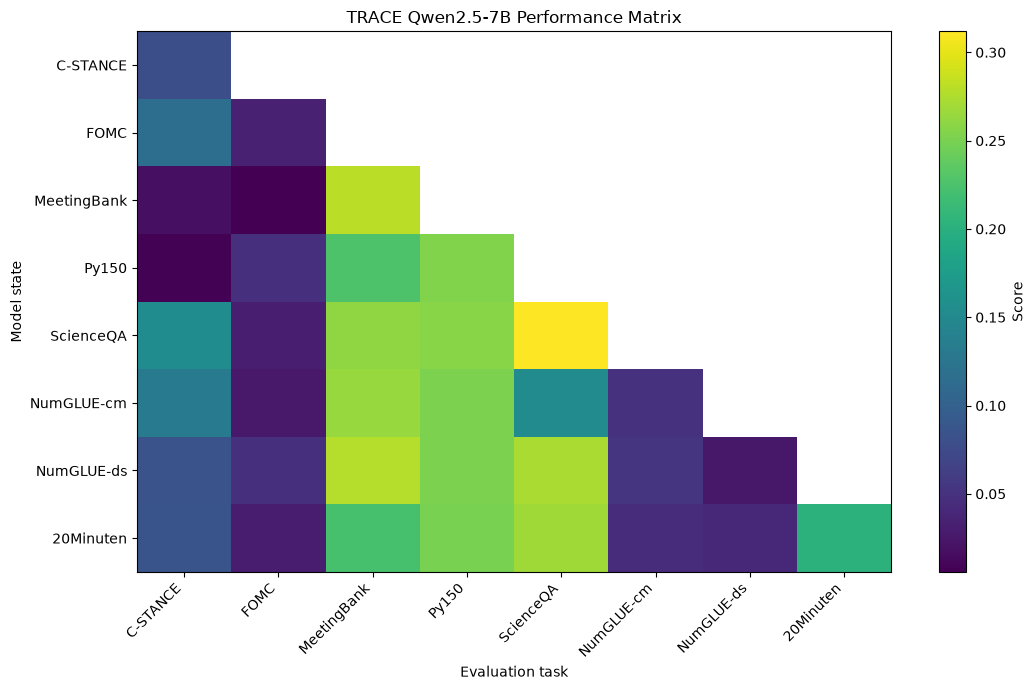

{
  "model": "Qwen/Qwen2.5-7B-Instruct",
  "mode": "ONE_DAY",
  "faar": false,
  "seed": 42,
  "config": {
    "train": 1000,
    "eval": 500,
    "eval_items": 150,
    "replay": 200,
    "max_len": 768,
    "new_tokens": 64
  },
  "tasks": [
    "C-STANCE",
    "FOMC",
    "MeetingBank",
    "Py150",
    "ScienceQA",
    "NumGLUE-cm",
    "NumGLUE-ds",
    "20Minuten"
  ],
  "OP": 0.1431944297689205,
  "BWT": -0.01142503783599486,
  "gpu": "NVIDIA A40",
  "vram_gb": 44.42193603515625,
  "time": "2026-09-27 08:12:21"
}


In [14]:
import matplotlib.pyplot as plt
plt.figure(figsize=(11,7))
plt.imshow(MATRIX.astype(float).values,aspect='auto')
plt.xticks(range(8),TASKS,rotation=45,ha='right')
plt.yticks(range(8),TASKS)
plt.xlabel('Evaluation task')
plt.ylabel('Model state')
plt.title('TRACE Qwen2.5-7B Performance Matrix')
plt.colorbar(label='Score')
plt.tight_layout()
plt.savefig(OUT/'performance_matrix_heatmap.png',dpi=180,bbox_inches='tight')
plt.show()

manifest={
    'model':MODEL_NAME,
    'mode':RUN_MODE,
    'faar':ENABLE_FAAR,
    'seed':SEED,
    'config':CFG,
    'tasks':TASKS,
    'OP':OP,
    'BWT':BWT,
    'gpu':gpu,
    'vram_gb':vram,
    'time':time.strftime('%Y-%m-%d %H:%M:%S')
}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding="utf-8")
print(json.dumps(manifest,indent=2))


## 11. Package everything

The ZIP contains checkpoints/adapters, state, matrix, metrics, forgetting, predictions and manifest. Download it before ending the Colab session.


In [15]:
archive=shutil.make_archive(
    str(WORKSPACE_ROOT/f"{TAG}_RESULTS"),
    'zip',
    BASE
)
print(archive,round(os.path.getsize(archive)/1024**2,1),'MB')


/users/q/qaisarm/TRACE_QWEN_RUNS/ONE_DAY_BASELINE_RESULTS.zip 1171.3 MB


# Practical plan for today

### Phase A — 15–30 minutes
Run `SMOKE` end-to-end. Confirm the notebook prints **8/8 resolved tasks**, loads Qwen, trains task 1, evaluates, and creates a checkpoint.

### Phase B — main run
Set `RUN_MODE = "ONE_DAY"`. This uses 1,000 train / 500 eval examples per task and one epoch. Let it run.

### Phase C — baseline comparison
Fresh runtime, set `ENABLE_FAAR=False`, keep the exact same mode/seed/model/config. Run again.

### Phase D — optional full-scale
Only if the two controlled runs finish comfortably, use `PAPER_SCALE` (5,000 train / 2,000 eval caps).

### Final table
| Method | Model | Replay | Train/task | OP | BWT |
|---|---|---|---:|---:|---:|
| Sequential LoRA | Qwen2.5-7B | No | 1,000 | ... | ... |
| FAAR | Qwen2.5-7B | Adaptive | 1,000 | ... | ... |

Keep the same benchmark order and configuration for the comparison.


## References

TRACE: *TRACE: A Comprehensive Benchmark for Continual Learning in Large Language Models*, arXiv:2310.06762.

Official implementation: BeyonderXX/TRACE.

Qwen2.5-7B-Instruct: official Qwen/Hugging Face model card.


## 📊 Report-ready summary table

This creates a compact table you can use directly when comparing runs.


In [16]:
forgetting_df=pd.DataFrame(forget)
mean_forgetting_value=(
    float(forgetting_df["forgetting"].mean())
    if not forgetting_df.empty else float("nan")
)

summary = pd.DataFrame([{
    "Method": "Qwen2.5-7B + " + ("FAAR" if ENABLE_FAAR else "Sequential"),
    "Model": MODEL_NAME.split("/")[-1],
    "Train/task": CFG["train"],
    "Eval/task": CFG["eval"],
    "Replay": "Adaptive" if ENABLE_FAAR else "None",
    "OP": OP,
    "BWT": BWT,
    "Mean Forgetting": mean_forgetting_value,
    "Tasks": len(TASKS),
}])

display(summary.style.format({
    "OP":"{:.4f}",
    "BWT":"{:.4f}",
    "Mean Forgetting":"{:.4f}",
}))
summary.to_csv(OUT/"summary_table.csv", index=False)


,Method,Model,Train/task,Eval/task,Replay,OP,BWT,Mean Forgetting,Tasks
0,Qwen2.5-7B + Sequential,Qwen2.5-7B-Instruct,1000,500,None,0.1432,-0.0114,0.0114,8


## 📈 Plot 1 — Performance across the continual-learning stream

Each point is the mean score over the tasks observed so far after learning another task.


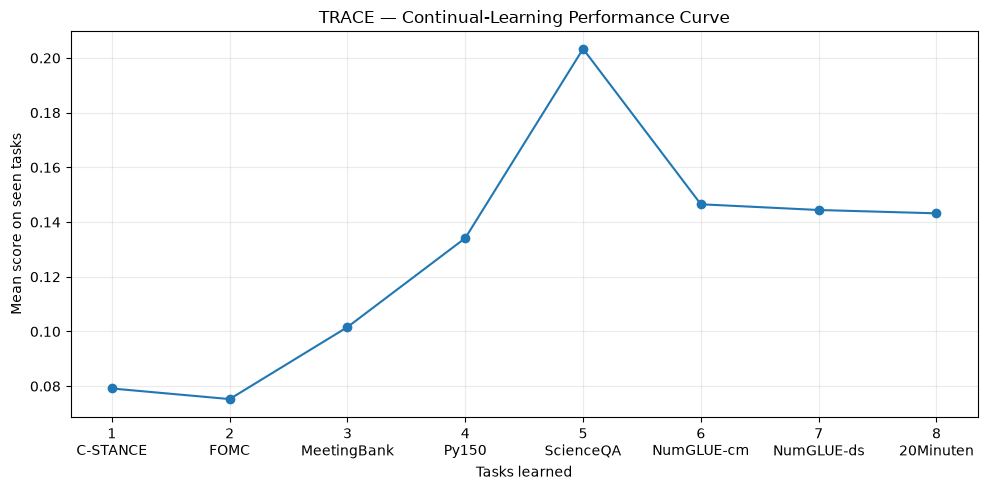

In [17]:
curve=[]
for i,state_task in enumerate(TASKS):
    vals=[MATRIX.loc[state_task,t] for t in TASKS[:i+1]
          if pd.notna(MATRIX.loc[state_task,t])]
    curve.append(float(np.mean(vals)) if vals else np.nan)

plt.figure(figsize=(10,5))
plt.plot(range(1,len(TASKS)+1), curve, marker="o")
plt.xticks(range(1,len(TASKS)+1), [f"{i+1}\n{t}" for i,t in enumerate(TASKS)])
plt.xlabel("Tasks learned")
plt.ylabel("Mean score on seen tasks")
plt.title("TRACE — Continual-Learning Performance Curve")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT/"performance_curve.png", dpi=180, bbox_inches="tight")
plt.show()


## 📉 Plot 2 — Task-level forgetting

Positive values mean that the task ended below its score immediately after it was learned.


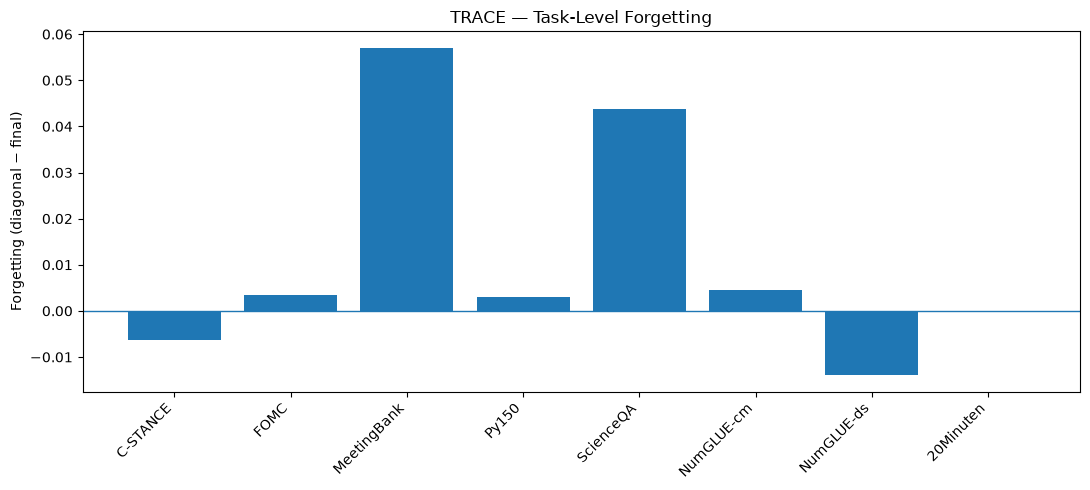

In [18]:
fg=pd.DataFrame(forget).rename(columns={"task":"Task","forgetting":"Forgetting"})

if fg.empty:
    print("No forgetting values available yet.")
else:
    plt.figure(figsize=(11,5))
    plt.bar(fg["Task"], fg["Forgetting"])
    plt.axhline(0, linewidth=1)
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Forgetting (diagonal − final)")
    plt.title("TRACE — Task-Level Forgetting")
    plt.tight_layout()
    plt.savefig(OUT/"forgetting_by_task.png", dpi=180, bbox_inches="tight")
    plt.show()


## 🔬 Direct Baseline vs FAAR comparison

After completing **two separate runs**, arrange them as:

```text
/content/comparison_runs/
    baseline/
        metrics.csv
        forgetting.csv
        performance_matrix.csv
    faar/
        metrics.csv
        forgetting.csv
        performance_matrix.csv
```

The next cell automatically creates:
- OP/BWT comparison table
- mean forgetting comparison
- OP/BWT bar chart
- per-task forgetting chart


In [19]:
# Preserve the original comparison concept while making it portable.
# On Colab this remains /content/comparison_runs; on CNAM it is under the workspace.
COMPARISON_ROOT = Path("/content/comparison_runs") if IS_COLAB else WORKSPACE_ROOT/"comparison_runs"
COMPARISON_ROOT.mkdir(parents=True,exist_ok=True)
COMPARE_OUT = COMPARISON_ROOT/"comparison_outputs"
COMPARE_OUT.mkdir(parents=True,exist_ok=True)

def load_method_result(name):
    # First support the original manually arranged comparison folders.
    root=COMPARISON_ROOT/name
    mp,fp,matp=root/"metrics.csv",root/"forgetting.csv",root/"performance_matrix.csv"

    # If those are absent, automatically use this notebook's matching run folders.
    if not (mp.exists() and fp.exists() and matp.exists()):
        tag=f"{RUN_MODE}_{'BASELINE' if name=='baseline' else 'FAAR'}"
        root=WORKSPACE_ROOT/tag/"run"/"results"
        mp,fp,matp=root/"metrics.csv",root/"forgetting.csv",root/"performance_matrix.csv"

    if not (mp.exists() and fp.exists() and matp.exists()): return None
    return {
        "metrics":pd.read_csv(mp),
        "forgetting":pd.read_csv(fp),
        "matrix":pd.read_csv(matp,index_col=0)
    }

baseline_r=load_method_result("baseline")
faar_r=load_method_result("faar")

if baseline_r is None or faar_r is None:
    print("Baseline/FAAR comparison folders are not present yet.")
    print("Finish both matching runs first.")
    print("Baseline:",WORKSPACE_ROOT/f"{RUN_MODE}_BASELINE"/"run"/"results")
    print("FAAR:",WORKSPACE_ROOT/f"{RUN_MODE}_FAAR"/"run"/"results")
else:
    def metric_value(r,name):
        m=r["metrics"]
        if name in m.columns and len(m):
            return float(m[name].iloc[0])
        if {"metric","value"}.issubset(m.columns):
            x=m.loc[m["metric"]==name,"value"]
            return float(x.iloc[0]) if len(x) else np.nan
        return np.nan

    comparison=pd.DataFrame([
        {
            "Method":"Sequential QLoRA (Baseline)",
            "OP":metric_value(baseline_r,"OP"),
            "BWT":metric_value(baseline_r,"BWT"),
            "Mean Forgetting":baseline_r["forgetting"]["forgetting"].mean()
        },
        {
            "Method":"Qwen2.5-7B + FAAR (Contribution)",
            "OP":metric_value(faar_r,"OP"),
            "BWT":metric_value(faar_r,"BWT"),
            "Mean Forgetting":faar_r["forgetting"]["forgetting"].mean()
        }
    ])

    display(comparison.style.format({
        "OP":"{:.4f}",
        "BWT":"{:.4f}",
        "Mean Forgetting":"{:.4f}"
    }))
    comparison.to_csv(COMPARE_OUT/"baseline_vs_faar.csv",index=False)

    metric_names=["OP","BWT"]
    x=np.arange(len(metric_names))
    width=.36

    plt.figure(figsize=(9,5))
    for j,method in enumerate(comparison["Method"]):
        vals=comparison.loc[comparison["Method"]==method,metric_names].values[0]
        plt.bar(x+(j-.5)*width,vals,width,label=method)
    plt.xticks(x,metric_names)
    plt.ylabel("Score")
    plt.title("Baseline vs FAAR — OP and BWT")
    plt.legend()
    plt.tight_layout()
    plt.savefig(COMPARE_OUT/"baseline_vs_faar_OP_BWT.png",dpi=180,bbox_inches="tight")
    plt.show()

    merged=baseline_r["forgetting"].merge(
        faar_r["forgetting"],on="task",suffixes=("_baseline","_faar")
    )

    x=np.arange(len(merged))
    plt.figure(figsize=(11,5))
    plt.bar(x-width/2,merged["forgetting_baseline"],width,label="Sequential baseline")
    plt.bar(x+width/2,merged["forgetting_faar"],width,label="FAAR")
    plt.axhline(0,linewidth=1)
    plt.xticks(x,merged["task"],rotation=45,ha="right")
    plt.ylabel("Forgetting")
    plt.title("Per-Task Forgetting — Baseline vs FAAR")
    plt.legend()
    plt.tight_layout()
    plt.savefig(COMPARE_OUT/"baseline_vs_faar_forgetting.png",dpi=180,bbox_inches="tight")
    plt.show()

    display(merged)


Baseline/FAAR comparison folders are not present yet.
Finish both matching runs first.
Baseline: /users/q/qaisarm/TRACE_QWEN_RUNS/ONE_DAY_BASELINE/run/results
FAAR: /users/q/qaisarm/TRACE_QWEN_RUNS/ONE_DAY_FAAR/run/results


## 📝 Report-ready interpretation guide

Use the actual generated values rather than deciding the conclusion beforehand.

### Implementation
- TRACE 8-task continual-learning stream
- Qwen2.5-7B-Instruct
- 4-bit QLoRA
- fixed task order
- identical training/evaluation budgets

### Contribution
**FAAR (Forgetting-Aware Adaptive Replay)** dynamically reallocates replay toward tasks showing larger measured forgetting.

### Main comparison
Compare:
1. OP
2. BWT
3. Mean forgetting
4. Per-task forgetting
5. Performance matrices

Do not claim an improvement unless the measured results support it.
